# 09 图像检索：图片怎样变成向量，再找到相似图片

学习目标：观察 RGB/HSV 数值，亲手提取向量、计算余弦相似度、返回 Top-K 并评价。
本课使用可复现的几何图像图库；另提供项目内真实照片的查询实验。不下载权重。
这是**颜色与空间外观特征基线**，不具备 CLIP 等模型的语义理解能力。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 原始水果输入：本课以橘子为检索例子

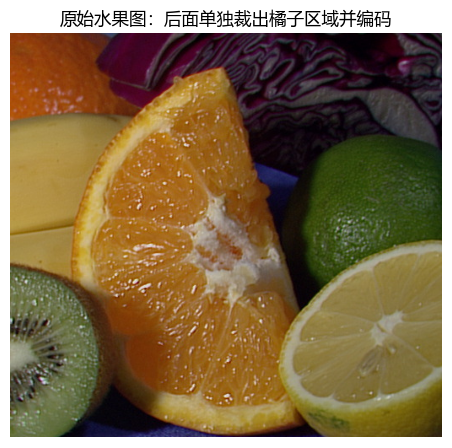

In [2]:
from pathlib import Path
import cv2, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists())
fruit_path = ROOT / "assets/photos/fruits.jpg"
fruit_bgr = cv2.imread(str(fruit_path)); assert fruit_bgr is not None, fruit_path
fruit_rgb = cv2.cvtColor(fruit_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 5)); plt.imshow(fruit_rgb); plt.title("原始水果图：后面单独裁出橘子区域并编码"); plt.axis("off"); plt.show()

## 1. 准备输入：图库与独立查询图片

圆、方形、三角形各用红绿蓝生成多张图，图库与查询使用不同随机种子，标签仅用于评估。


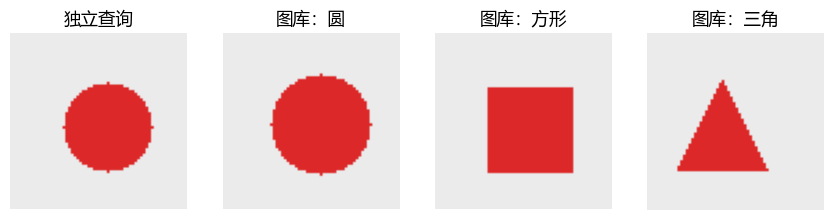

输入形状: (64, 64, 3) 类型: uint8
查询中心 3×3 RGB 矩阵:
 [[[220  40  40]
  [220  40  40]
  [220  40  40]]

 [[220  40  40]
  [220  40  40]
  [220  40  40]]

 [[220  40  40]
  [220  40  40]
  [220  40  40]]]


In [3]:
def make_picture(shape, color, seed):
    rng = np.random.default_rng(seed)
    image = np.full((64, 64, 3), 235, np.uint8)
    center = (int(rng.integers(27, 37)), int(rng.integers(27, 37)))
    size = int(rng.integers(15, 22))
    if shape == 0:
        cv2.circle(image, center, size, color, -1)
    elif shape == 1:
        cv2.rectangle(image, (center[0]-size, center[1]-size), (center[0]+size, center[1]+size), color, -1)
    else:
        pts = np.array([[center[0], center[1]-size], [center[0]-size, center[1]+size], [center[0]+size, center[1]+size]])
        cv2.fillPoly(image, [pts], color)
    return image  # 此处颜色直接按 RGB 解释

colors = [(220, 40, 40), (40, 180, 40), (40, 70, 220)]
gallery, labels = [], []
for shape in range(3):
    for color_id, color in enumerate(colors):
        for sample in range(4):
            gallery.append(make_picture(shape, color, 100*shape+10*color_id+sample))
            labels.append((shape, color_id))
query = make_picture(0, colors[0], 999)
fig, axs = plt.subplots(1, 4, figsize=(10, 3))
for ax, im, title in zip(axs, [query, gallery[0], gallery[12], gallery[24]], ["独立查询", "图库：圆", "图库：方形", "图库：三角"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
save_figure("09_retrieval_inputs")
print("输入形状:", query.shape, "类型:", query.dtype)
print("查询中心 3×3 RGB 矩阵:\n", query[30:33, 30:33])


## 2. 编码：从像素到一个固定长度向量

先用饱和度分出彩色前景，再计算前景颜色直方图和紧致边界框内的二值轮廓图，拼接后做 L2 归一化。
颜色特征负责“颜色像不像”，轮廓特征保留“形状像不像”。前景提取依赖本课灰色背景的假设，不能直接用于任意真实场景。

数值怎么读：RGB 输入是 `[64,64,3]`，最后一维依次是红、绿、蓝；HSV 直方图有 `12×4=48` 项，轮廓缩略图有 `12×12=144` 项，拼成 192 维向量。36 张图库组成 `[36,192]` 矩阵，乘以 `[192]` 查询向量得到 36 个相似度。归一化后的特征值已不是原始像素值，不能按颜色强度解释。


In [4]:
def encode(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    mask = (hsv[..., 1] > 60).astype(np.uint8)
    if not mask.any():
        mask = np.ones(image.shape[:2], np.uint8)
    hist = cv2.calcHist([hsv], [0, 1], mask, [12, 4], [0, 180, 0, 256]).reshape(-1)
    hist = hist / (np.linalg.norm(hist)+1e-8)
    x, y, w, h = cv2.boundingRect(mask)
    spatial = cv2.resize(mask[y:y+h, x:x+w].astype(np.float32), (12, 12), interpolation=cv2.INTER_AREA).reshape(-1)
    spatial /= np.linalg.norm(spatial)+1e-8
    vector = np.concatenate([hist, spatial])
    return vector / (np.linalg.norm(vector)+1e-8)

vectors = np.stack([encode(im) for im in gallery])
q = encode(query)
print("图库矩阵 [图像数, 特征维数]:", vectors.shape)
print("查询向量前 12 项:", np.round(q[:12], 3))
print("L2 范数:", np.linalg.norm(q))


图库矩阵 [图像数, 特征维数]: (36, 192)
查询向量前 12 项: [0.    0.    0.    0.707 0.    0.    0.    0.    0.    0.    0.    0.   ]
L2 范数: 1.0


## 3. 检索：余弦相似度与排序

归一化后，$s(q,v)=q^Tv$。分数表示特征相似程度，不是“属于该类别的概率”。


Top-5 索引: [ 3  0  2  1 15] 分数: [1.    1.    1.    1.    0.943]


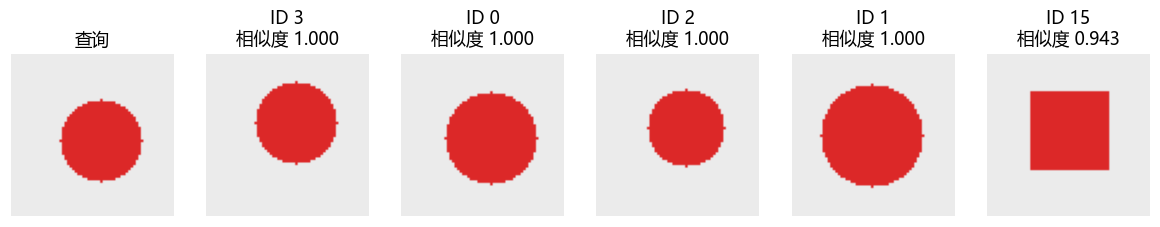

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/09_retrieval_results.png')

In [5]:
scores = vectors @ q
top = np.argsort(-scores)[:5]
print("Top-5 索引:", top, "分数:", np.round(scores[top], 3))
fig, axs = plt.subplots(1, 6, figsize=(14, 3))
axs[0].imshow(query); axs[0].set_title("查询"); axs[0].axis("off")
for ax, idx in zip(axs[1:], top):
    ax.imshow(gallery[idx]); ax.set_title(f"ID {idx}\n相似度 {scores[idx]:.3f}"); ax.axis("off")
save_figure("09_retrieval_results")


## 4. 评价：在九个独立查询上计算 Precision@K 与 Recall@K

相关图片定义为“形状和颜色都相同”；图库每组有 4 张。
Precision@K 衡量返回结果中相关结果的比例；Recall@K 衡量图库相关图片被找回的比例。


In [6]:
precision, recall = [], []
for shape in range(3):
    for c in range(3):
        test_query = make_picture(shape, colors[c], 2000+10*shape+c)
        rank = np.argsort(-(vectors @ encode(test_query)))[:4]
        relevant = sum(labels[i] == (shape, c) for i in rank)
        precision.append(relevant/4); recall.append(relevant/4)
print(f"独立查询 Precision@4={np.mean(precision):.3f}, Recall@4={np.mean(recall):.3f}")
assert vectors.shape[0] == len(labels) and np.isfinite(scores).all()


独立查询 Precision@4=1.000, Recall@4=1.000


## 5. 真实照片实验：相似变换能否被检索回来

同一张照片的亮度、缩放和旋转版本与三种形状一起进入图库。观察外观特征对旋转的敏感性。
这不是严格的语义检索评测；要评价语义检索应使用独立标注的真实图库。


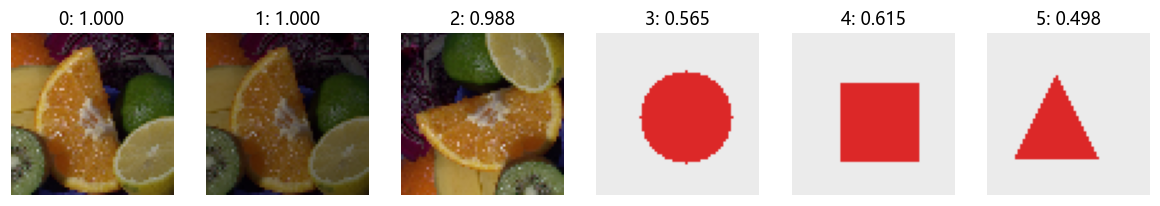

In [7]:
photo_path = ROOT / "assets/photos/fruits.jpg"
if photo_path.exists():
    photo = cv2.cvtColor(cv2.imread(str(photo_path)), cv2.COLOR_BGR2RGB)
    photo = cv2.resize(photo, (64, 64))
    candidates = [photo, np.clip(photo.astype(float)*0.65, 0, 255).astype(np.uint8), np.rot90(photo).copy(), *gallery[::12]]
    photo_scores = np.array([encode(im) @ encode(photo) for im in candidates])
    fig, axs = plt.subplots(1, len(candidates), figsize=(14, 3))
    for i, ax in enumerate(axs):
        ax.imshow(candidates[i]); ax.set_title(f"{i}: {photo_scores[i]:.3f}"); ax.axis("off")
    save_figure("09_retrieval_photo")
else:
    print("未找到可选真实照片；请运行项目的素材准备步骤。")


## 6. 学生练习与扩展

1. 修改特征权重、灰度缩略图大小，观察 Recall@4。
2. 把查询图变成灰度，解释为什么颜色特征失效。
3. 进阶：用 torchvision 预训练编码器替换 encode，保持检索与评价代码不变；下载权重前先确认网络和授权。

参考：[OpenCV 直方图计算](https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html)、[FAISS 项目](https://github.com/facebookresearch/faiss)。本课的小图库使用精确矩阵乘法，不依赖 FAISS。


## 橘子区域的 192 维向量（颜色直方图 + 空间占用）

橘子裁剪尺寸: (432, 308, 3) 特征向量维数: 192
向量前48维（12个色相桶×4个饱和度桶）: [0.003 0.057 0.083 0.181 0.003 0.113 0.421 0.503 0.002 0.079 0.01  0.001
 0.    0.002 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.001 0.007 0.    0.    0.003 0.018 0.007
 0.001 0.009 0.006 0.004 0.001 0.027 0.033 0.035 0.    0.013 0.019 0.062]
向量后144维（12×12空间占用）: [0.062 0.062 0.062 0.062 0.062 0.06  0.061 0.059 0.054 0.048 0.047 0.055
 0.062 0.062 0.062 0.062 0.062 0.062 0.062 0.062 0.062 0.052 0.049 0.039
 0.062 0.062 0.062 0.062 0.062 0.062 0.061 0.062 0.062 0.06  0.061 0.056
 0.062 0.062 0.062 0.062 0.062 0.062 0.061 0.062 0.062 0.062 0.062 0.061
 0.062 0.062 0.062 0.062 0.061 0.062 0.062 0.061 0.061 0.062 0.062 0.061
 0.062 0.062 0.062 0.062 0.061 0.061 0.059 0.037 0.035 0.061 0.062 0.062
 0.062 0.062 0.062 0.061 0.057 0.06  0.059 0.037 0.057 0.038 0.045 0.062
 0.056 0.062 0.062 0.06  0.057 0.062 0.061 0.047 0.034 0.042 0.053 0.062
 0.051 0.052 0.061 0.062 0.062 0.062 0.061 0.061 

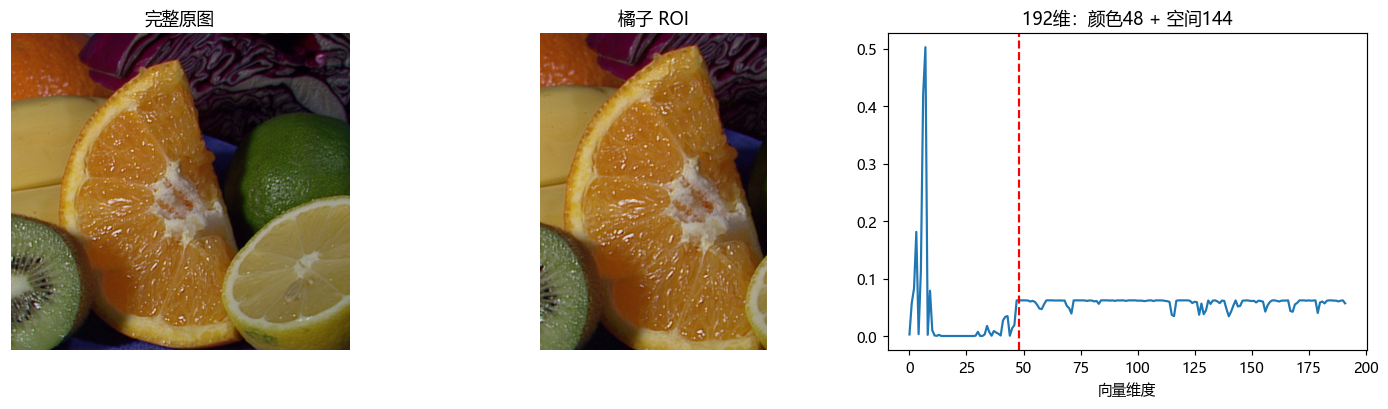

In [8]:
# 课程照片中橘子切片的矩形区域；展示的是显式特征，不是深度网络 embedding。
h, w = fruit_rgb.shape[:2]
orange_crop = fruit_rgb[int(.05*h):int(.95*h), int(.08*w):int(.68*w)]
orange_vector = encode(orange_crop)
print("橘子裁剪尺寸:", orange_crop.shape, "特征向量维数:", orange_vector.size)
print("向量前48维（12个色相桶×4个饱和度桶）:", np.round(orange_vector[:48], 3))
print("向量后144维（12×12空间占用）:", np.round(orange_vector[48:], 3))
fig, axs = plt.subplots(1, 3, figsize=(14, 4)); axs[0].imshow(fruit_rgb); axs[0].set_title("完整原图"); axs[1].imshow(orange_crop); axs[1].set_title("橘子 ROI"); axs[2].plot(orange_vector); axs[2].axvline(48, color="red", linestyle="--"); axs[2].set_title("192维：颜色48 + 空间144"); axs[2].set_xlabel("向量维度");
for ax in axs[:2]: ax.axis("off")
plt.tight_layout(); plt.show()